# Block 0 - Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8")


# Block 1 — Objective

The goal of this notebook is to perform an exploratory analysis of a real-world
time series dataset related to retail demand.

Specifically, we aim to:
- Understand the temporal structure of the data (trend, seasonality, noise)
- Identify differences across stores and products
- Detect potential anomalies or irregular patterns
- Assess data quality issues such as missing dates or inconsistent frequencies

This analysis will guide the feature engineering and modeling decisions in the
subsequent notebooks.


# Block 2 Load Data

In [3]:
# Load data
df = pd.read_csv("../data/raw/train.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(["store", "item", "date"])

df.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


# Block 3 — Dataset Overview

In [4]:

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    913000 non-null  datetime64[ns]
 1   store   913000 non-null  int64         
 2   item    913000 non-null  int64         
 3   sales   913000 non-null  int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 34.8 MB


,date,store,item,sales
count,913000,913000.000000,913000.000000,913000.000000
mean,2015-07-02 11:59:59.999999744,5.500000,25.500000,52.250287
min,2013-01-01 00:00:00,1.000000,1.000000,0.000000
25%,2014-04-02 00:00:00,3.000000,13.000000,30.000000
50%,2015-07-02 12:00:00,5.500000,25.500000,47.000000
75%,2016-10-01 00:00:00,8.000000,38.000000,70.000000
max,2017-12-31 00:00:00,10.000000,50.000000,231.000000
std,NaN,2.872283,14.430878,28.801144


In [6]:
# Range of dates
df["date"].min(), df["date"].max()


(Timestamp('2013-01-01 00:00:00'), Timestamp('2017-12-31 00:00:00'))

In [8]:
# Count unique stores and items
df["store"].nunique(), df["item"].nunique()


(10, 50)

# Block 4 - Time Series Exploration


<Axes: title={'center': 'Daily Sales — Store 1, Item 1'}, xlabel='date'>

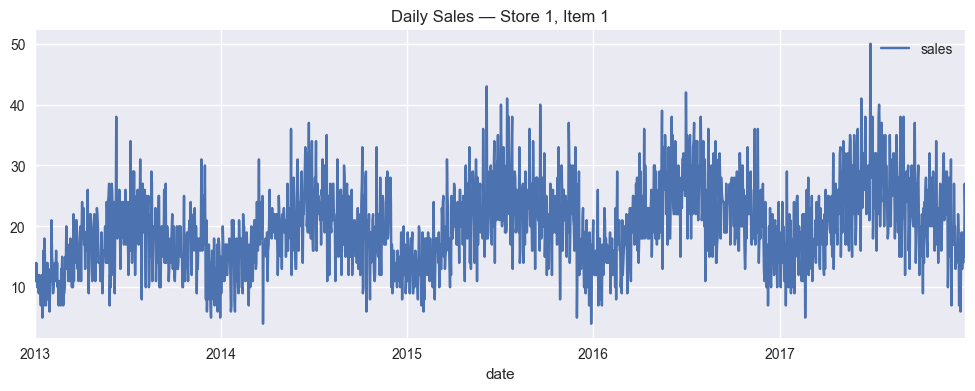

In [10]:
# Plot sales for a single store and item
example = df.query("store == 1 and item == 1")

example.plot(
    x="date",
    y="sales",
    figsize=(12,4),
    title="Daily Sales — Store 1, Item 1"
)

# Block 5 - Key Observations

- The dataset contains daily sales data with no missing dates
- Multiple independent time series exist for each (store, item) combination
- Clear seasonal patterns are visible
- The problem is framed as a multi-series demand forecasting task

## Block 6 - Next Steps

In the next notebook we will:
- Engineer time series features (lags, rolling statistics)
- Create a temporal train / validation split
- Prepare the dataset for forecasting models

